# Entrega 2 · Bank Marketing
## Del dato a la decisión
**Análisis exploratorio · 23 de septiembre de 2026**

**Negocio:** ¿qué características e historial se asocian con contratar un depósito a plazo fijo?
**Predicción:** ¿qué información disponible **antes de la llamada** puede usarse para anticipar `y`?

### Qué presentamos
El análisis incluye un perfil del dataset, **cuatro fichas de hipótesis** y una propuesta de variables
para predecir la contratación antes de la llamada.

| Ficha principal | Identificador | Pregunta | Tema |
|---|---|---|---|
| 1 | H1 | Negocio | Contratación entre clientes con éxito previo |
| 2 | E3 | Predicción | ¿`campaign` y `previous` son redundantes? |
| 3 | E4 | Negocio | Ocupación y sobrerrepresentación |
| 4 | H4 | Predicción | ¿La insistencia distingue las clases? |

**E1 (saldo) se desarrolla en el anexo de reserva**, fuera de las cuatro fichas de la defensa.

### Alcance del análisis
Este estudio es **exploratorio**. Cada ficha presenta una afirmación, una expectativa, una medida,
gráficos, resultados y una decisión. Las asociaciones observadas no prueban causalidad ni garantizan
capacidad predictiva fuera de muestra. No se entrena un modelo en esta etapa.

## 1 · Carga reproducible y contrato del dataset
Si `_bank_marketing_silver.csv` ya está en el entorno, se reutiliza. Si no está, se descarga de Drive
con `gdown` usando el ID indicado por el grupo: `1u41ru5WA5q68hXPKegyCY9Z3lAb7VqMn`.
La celda instala `gdown` únicamente si hace falta. El archivo debe permitir esa descarga;
el notebook no cambia permisos de Drive. Para subir el CSV manualmente en Colab, dejar `ID_DRIVE = ""`.

El origen es **Bank Marketing de UCI, versión bank-full (45.211 registros)**; el archivo utilizado es
el CSV `_bank_marketing_silver.csv`. No confundir con bank-additional (41.188 registros y otros códigos).
Cada fila es un **registro de contacto/campaña asociado a un cliente** y recoge características del último
contacto. `campaign` puede resumir varias llamadas: una fila no es necesariamente cada llamada individual.
`contact_id` identifica registros; no demuestra identidad única de personas.

In [1]:
from pathlib import Path
import hashlib, sys, platform, subprocess
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ARCHIVO = Path('_bank_marketing_silver.csv')
ID_DRIVE = '1u41ru5WA5q68hXPKegyCY9Z3lAb7VqMn'
if not ARCHIVO.exists():
    if ID_DRIVE:
        try:
            import gdown
        except ImportError:
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'gdown>=5.2,<6'])
            import gdown
        temporal = ARCHIVO.with_suffix('.csv.part')
        try:
            resultado = gdown.download(id=ID_DRIVE, output=str(temporal), quiet=False,
                                      use_cookies=False)
            if resultado is None or not temporal.exists() or temporal.stat().st_size == 0:
                raise RuntimeError('La descarga no produjo un archivo válido.')
            # Evita tratar una página de error de Drive como si fuera el dataset.
            cabecera = pd.read_csv(temporal, nrows=0)
            if not {'contact_id', 'y', 'poutcome', 'balance'}.issubset(cabecera.columns):
                raise ValueError('El archivo descargado no tiene el esquema del CSV silver.')
            temporal.replace(ARCHIVO)
        except Exception as exc:
            temporal.unlink(missing_ok=True)
            raise RuntimeError(
                'No se pudo descargar el CSV de Drive. Revisá ID/permisos/cuota o dejá '
                'ID_DRIVE vacío para subirlo manualmente en Colab.'
            ) from exc
    else:
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError('Colocá _bank_marketing_silver.csv junto al notebook.')
        subidos = files.upload()
        if ARCHIVO.name not in subidos or not ARCHIVO.exists():
            raise FileNotFoundError('Subí el CSV con el nombre _bank_marketing_silver.csv.')

df = pd.read_csv(ARCHIVO, na_values=['NaN', 'unknown'], keep_default_na=True)
esperadas = ['contact_id','age','job','marital','education','default','balance','housing',
             'loan','contact','day','month','duration','campaign','pdays','previous','poutcome','y']
assert set(df.columns) == set(esperadas), 'Revisar versión/esquema del CSV.'
assert df['y'].notna().all() and set(df['y'].unique()) == {'yes','no'}
assert df['contact_id'].notna().all() and not df['contact_id'].duplicated().any()
assert df['campaign'].ge(1).all() and df['previous'].ge(0).all()
assert (df['pdays'].eq(-1) | df['pdays'].ge(0)).all()
y = df['y'].eq('yes').astype(int)
base = float(y.mean())
sha = hashlib.sha256(ARCHIVO.read_bytes()).hexdigest()
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_colwidth', 120)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .18, 'font.size': 10})
COLORES = {'rojo':'#b44949', 'amarillo':'#b58115', 'verde':'#168078'}
print('Python', platform.python_version(), '| pandas',pd.__version__,'| numpy',np.__version__,
      '| matplotlib',matplotlib.__version__)
print('Archivo:', ARCHIVO.name, '| SHA256:', sha)
print('Filas y columnas:', df.shape)
display(df.head(3))

Python 3.12.3 | pandas 3.0.6 | numpy 2.5.3 | matplotlib 3.11.2
Archivo: _bank_marketing_silver.csv | SHA256: f749e8bee883e1b98ba913fbdf26a91e25049b11a650940bdaef302e39a97e35
Filas y columnas: (45211, 18)


,contact_id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,CNT_000001,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,CNT_000002,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,CNT_000003,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no


## 2 · Perfil: los números que tenemos que defender
El tamaño, los tipos, los nulos, los duplicados y las distribuciones se calculan sobre el CSV cargado.

,tipo,nulos,% nulos,valores distintos
contact_id,str,0,0.000,45211
age,int64,0,0.000,77
job,str,288,0.637,11
marital,str,0,0.000,3
education,str,1857,4.107,3
default,str,0,0.000,2
balance,int64,0,0.000,7168
housing,str,0,0.000,2
loan,str,0,0.000,2
contact,str,13020,28.798,2


Cantidad de columnas por tipo:


str      11
int64     7
Name: columnas, dtype: int64

Numéricas esperadas almacenadas como texto: ninguna (verificación automática).
Constantes (nunique <= 1): []
Duplicados de contact_id: 0
Filas repetidas sin considerar el ID: 0
No se eliminan filas por coincidencia de atributos: pueden corresponder a personas distintas.


,n,%
y,,
no,39922,88.302
yes,5289,11.698


previous    41.846
balance      8.360
campaign     4.899
duration     3.144
pdays        2.616
age          0.685
day          0.093
Name: asimetría, dtype: float64

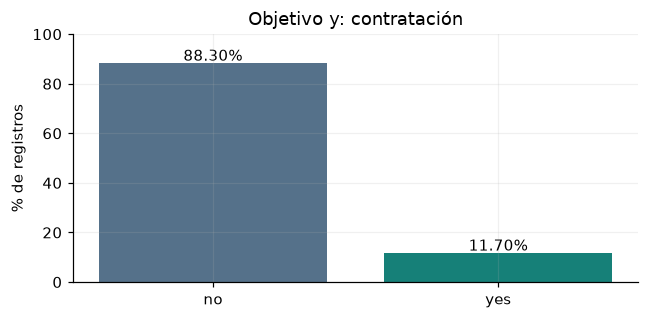

In [2]:
perfil = pd.DataFrame({'tipo':df.dtypes.astype(str), 'nulos':df.isna().sum(),
                      '% nulos':df.isna().mean()*100, 'valores distintos':df.nunique()})
display(perfil.round(3))
print('Cantidad de columnas por tipo:')
display(df.dtypes.astype(str).value_counts().rename('columnas'))
numericas = ['age','balance','day','duration','campaign','pdays','previous']
assert all(pd.api.types.is_numeric_dtype(df[c]) for c in numericas)
print('Numéricas esperadas almacenadas como texto: ninguna (verificación automática).')
print('Constantes (nunique <= 1):', df.columns[df.nunique() <= 1].tolist())
print('Duplicados de contact_id:', int(df['contact_id'].duplicated().sum()))
print('Filas repetidas sin considerar el ID:', int(df.drop(columns='contact_id').duplicated().sum()))
print('No se eliminan filas por coincidencia de atributos: pueden corresponder a personas distintas.')
objetivo = df['y'].value_counts().rename('n').to_frame()
objetivo['%'] = objetivo['n']/len(df)*100
display(objetivo.round(3))
skew = df[numericas].skew().sort_values(ascending=False).rename('asimetría')
display(skew.round(3))
fig, ax = plt.subplots(figsize=(6,3))
ax.bar(objetivo.index, objetivo['%'], color=['#55718a','#168078'])
for i, v in enumerate(objetivo['%']): ax.text(i,v+1,f'{v:.2f}%',ha='center')
ax.set(ylabel='% de registros',title='Objetivo y: contratación',ylim=(0,100))
plt.tight_layout(); plt.show()

### Asimetrías: mirar la distribución antes de elegir un movimiento
Cada variable de la tabla tiene su gráfico, en el mismo orden:

- **Rango completo:** muestra todos los valores. Para las colas muy largas, sólo el eje de
  **frecuencia** se presenta en escala logarítmica para hacer visibles los casos poco frecuentes.
  **Los valores de la variable no se transforman.**
- **Detalle central:** muestra los valores entre los percentiles 1 y 99, con frecuencia lineal.
  Se indica cuántos registros quedan fuera de esa vista. Es un zoom descriptivo: no se borran filas
  ni se recalcula la asimetría global sobre el recorte.
- **Media y mediana:** las líneas ayudan a ver cuánto se desplaza el promedio por la cola.
- **`pdays`:** a la izquierda se cuenta cuántos registros tienen o no historial; a la derecha
  se dibujan sólo los días reales. Su asimetría sin `−1` se informa aparte de la tabla cruda.

Para `balance` se marca el cero y se informan negativos, ceros y positivos. Una cola larga o varios
picos **no prueban por sí solos que haya poblaciones diferentes**. Estos gráficos sirven para elegir
una explicación a contrastar: escala, grupos con comportamientos distintos o ambas. No imponen un logaritmo.

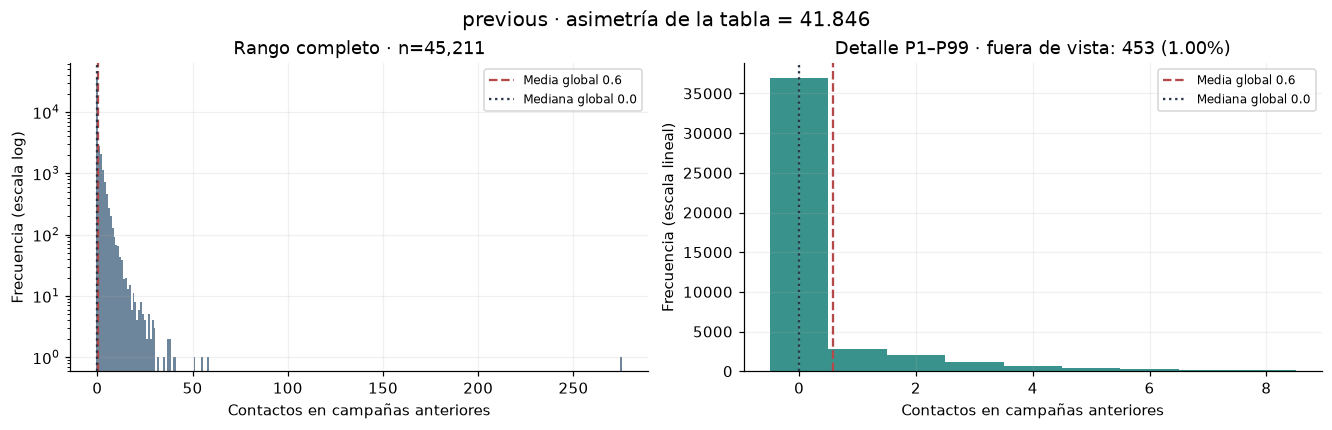

balance · cantidades y porcentajes (no son poblaciones demostradas):
  Negativos: 3,766 (8.33%)
  Ceros: 3,514 (7.77%)
  Positivos: 37,931 (83.90%)


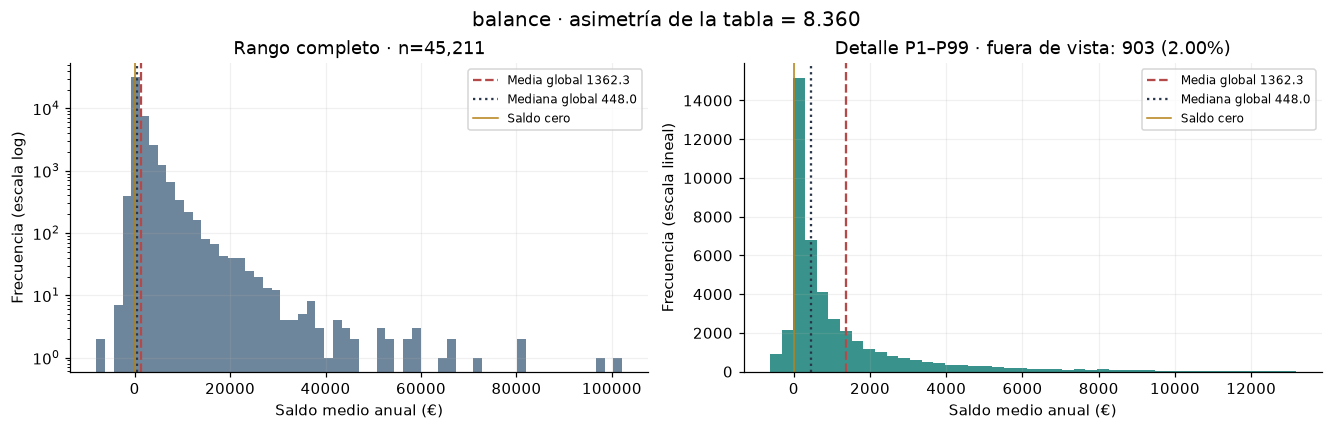

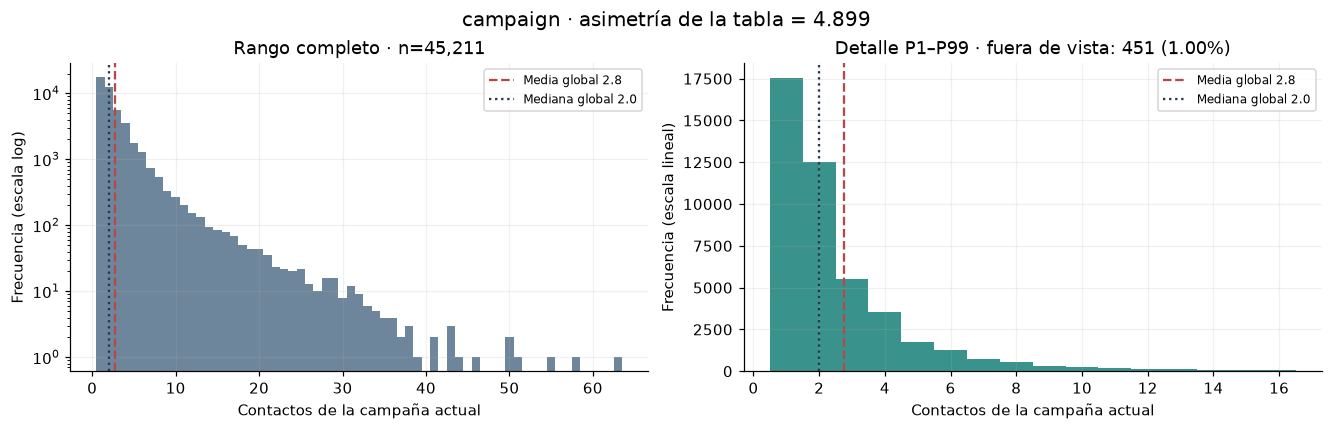

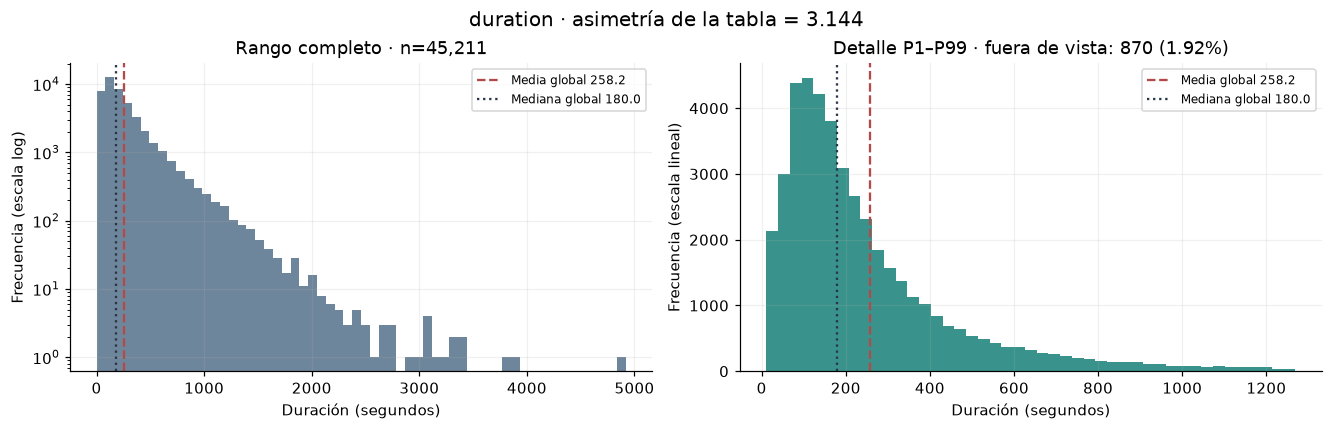

pdays: skew crudo=2.616; sólo días reales=0.693. Los 36,954 códigos −1 no son días negativos.


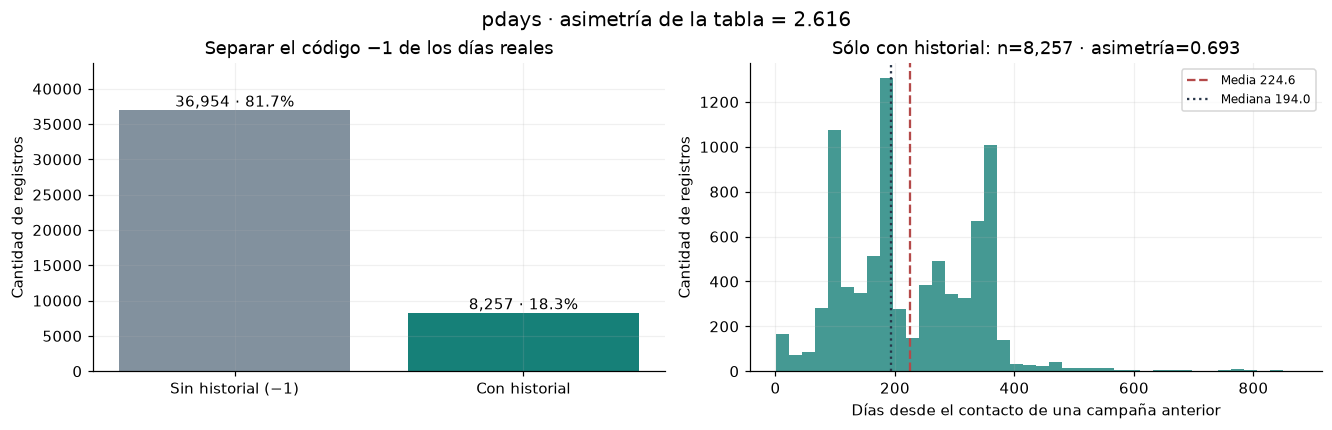

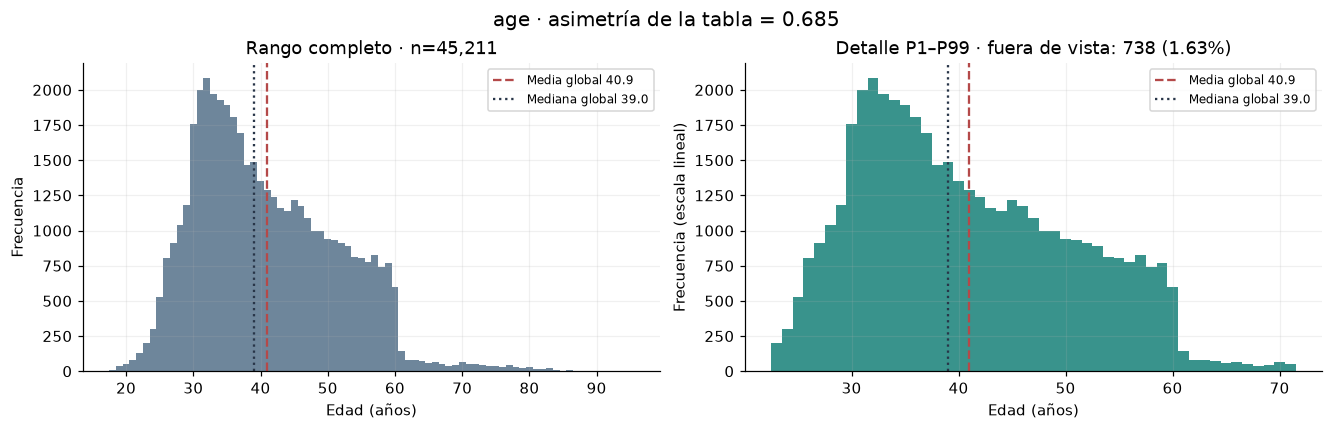

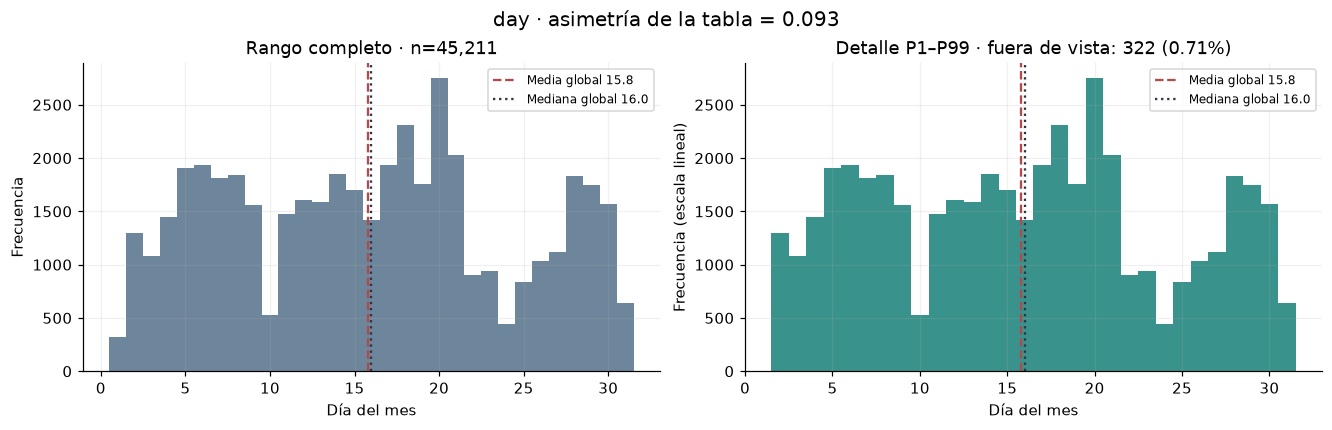

In [3]:
# Sólo diagnóstico visual: no se modifican df ni las medidas globales.
unidades = {'previous':'Contactos en campañas anteriores', 'balance':'Saldo medio anual (€)',
            'campaign':'Contactos de la campaña actual', 'duration':'Duración (segundos)',
            'pdays':'Días desde el contacto de una campaña anterior',
            'age':'Edad (años)', 'day':'Día del mes'}
discretas = {'previous','campaign','age','day'}
colas_largas = {'previous','balance','campaign','duration'}

for columna in skew.index:
    serie = df[columna].dropna()
    fig, axes = plt.subplots(1,2,figsize=(12,3.8),layout='constrained')
    fig.suptitle(f'{columna} · asimetría de la tabla = {skew[columna]:.3f}',fontsize=13)

    if columna == 'pdays':
        nunca = int(serie.eq(-1).sum())
        dias = serie[serie.ne(-1)]
        barras = axes[0].bar(['Sin historial (−1)','Con historial'],[nunca,len(dias)],
                             color=['#82919e','#168078'])
        for barra,n in zip(barras,[nunca,len(dias)]):
            axes[0].text(barra.get_x()+barra.get_width()/2,n,
                         f'{n:,} · {n/len(serie):.1%}',ha='center',va='bottom')
        axes[0].set(title='Separar el código −1 de los días reales',ylabel='Cantidad de registros',
                    ylim=(0,max(nunca,len(dias))*1.18))
        axes[1].hist(dias,bins=40,color='#168078',alpha=.8)
        axes[1].axvline(dias.mean(),color='#b44949',ls='--',label=f'Media {dias.mean():.1f}')
        axes[1].axvline(dias.median(),color='#283548',ls=':',label=f'Mediana {dias.median():.1f}')
        axes[1].set(title=f'Sólo con historial: n={len(dias):,} · asimetría={dias.skew():.3f}',
                    xlabel=unidades[columna],ylabel='Cantidad de registros')
        axes[1].legend(fontsize=8)
        print(f'pdays: skew crudo={serie.skew():.3f}; sólo días reales={dias.skew():.3f}. '
              f'Los {nunca:,} códigos −1 no son días negativos.')
    else:
        q1,q99 = serie.quantile([.01,.99])
        central = serie[serie.between(q1,q99)]
        fuera = len(serie)-len(central)
        bins_completo = (np.arange(serie.min()-.5,serie.max()+1.5,1)
                         if columna in discretas else 60)
        bins_central = (np.arange(central.min()-.5,central.max()+1.5,1)
                        if columna in discretas else 45)
        axes[0].hist(serie,bins=bins_completo,color='#55718a',alpha=.85)
        axes[1].hist(central,bins=bins_central,color='#168078',alpha=.85)
        if columna in colas_largas:
            axes[0].set_yscale('log')
        axes[0].set(title=f'Rango completo · n={len(serie):,}',
                    ylabel='Frecuencia (escala log)' if columna in colas_largas else 'Frecuencia')
        axes[1].set(title=f'Detalle P1–P99 · fuera de vista: {fuera:,} ({fuera/len(serie):.2%})',
                    ylabel='Frecuencia (escala lineal)')
        for ax,vista in zip(axes,[serie,central]):
            # Se mantiene la media/mediana GLOBAL, no las del recorte.
            if vista.min() <= serie.mean() <= vista.max():
                ax.axvline(serie.mean(),color='#b44949',ls='--',label=f'Media global {serie.mean():.1f}')
            if vista.min() <= serie.median() <= vista.max():
                ax.axvline(serie.median(),color='#283548',ls=':',label=f'Mediana global {serie.median():.1f}')
            if columna=='balance':
                ax.axvline(0,color='#b58115',lw=1,label='Saldo cero')
            ax.set_xlabel(unidades[columna]);ax.legend(fontsize=8)
        if columna=='balance':
            print('balance · cantidades y porcentajes (no son poblaciones demostradas):')
            for etiqueta,mascara in [('Negativos',serie.lt(0)),('Ceros',serie.eq(0)),('Positivos',serie.gt(0))]:
                print(f'  {etiqueta}: {int(mascara.sum()):,} ({mascara.mean():.2%})')
    plt.show()

### Nulos reales, nulos estructurales y códigos
- **`poutcome`:** sin campaña previa no puede haber resultado previo. Se verifica con `pdays == -1`.
  No todos sus nulos deben llamarse «nunca contactado»: separaremos los faltantes con historial.
- **`contact`:** canal no registrado. Su ausencia **no significa que no existió una llamada**;
  se conserva como desconocido. Una tasa distinta no identifica por sí sola la causa del faltante.
- **`education`:** nivel educativo no registrado; no corresponde inferir que el cliente no tiene estudios.
- **`job`:** ocupación no registrada; no corresponde imputar desempleo.

El CSV contiene marcadores `NaN`. La documentación de UCI incluye categorías `unknown`.
El archivo no permite determinar todas las causas de ausencia: se distingue lo verificable por
consistencia entre columnas de aquello cuyo motivo no está registrado.

In [4]:
historial = df['pdays'].ne(-1)
inconsistentes = df['poutcome'].isna() & historial
sin_historia = ~historial
print('Sin contacto en campaña previa:', int(sin_historia.sum()))
print('poutcome nulo sin historial:', int((df.poutcome.isna() & sin_historia).sum()))
print('poutcome nulo CON historial:', int(inconsistentes.sum()))
print('pdays y previous discrepan sobre existencia de historial:',
      int((historial != df.previous.gt(0)).sum()))
display(df.loc[inconsistentes, ['contact_id','pdays','previous','poutcome']])
poutcome_limpio = df['poutcome'].fillna('desconocido_con_historial').copy()
poutcome_limpio.loc[sin_historia & df.poutcome.isna()] = 'sin_historial'
print('Tres columnas con mayor porcentaje de nulos:')
display(perfil.sort_values('% nulos',ascending=False).head(3))
print('El -1 de pdays es un código, no días negativos. Su skew crudo no describe sólo días reales.')
display(df.loc[historial, 'pdays'].describe().to_frame('pdays con historial'))

Sin contacto en campaña previa: 36954
poutcome nulo sin historial: 36954
poutcome nulo CON historial: 5
pdays y previous discrepan sobre existencia de historial: 0


,contact_id,pdays,previous,poutcome
40658,CNT_040659,98,1,NaN
41821,CNT_041822,168,5,NaN
42042,CNT_042043,188,2,NaN
43978,CNT_043979,416,2,NaN
45021,CNT_045022,528,7,NaN


Tres columnas con mayor porcentaje de nulos:


,tipo,nulos,% nulos,valores distintos
poutcome,str,36959,81.747805,3
contact,str,13020,28.798301,2
education,str,1857,4.107407,3


El -1 de pdays es un código, no días negativos. Su skew crudo no describe sólo días reales.


,pdays con historial
count,8257.000000
mean,224.577692
std,115.344035
min,1.000000
25%,133.000000
50%,194.000000
75%,327.000000
max,871.000000


## 3 · Reglas comunes: un solo semáforo
Para calcular las medidas y clasificar su magnitud se definen las siguientes funciones:
- `separacion(x, y)`: recibe las **dos muestras**, por ejemplo saldos de quienes contratan y de quienes no.
- `eta2(numerica, categoria)`: recibe la variable numérica y la columna que define los grupos;
  aquí se llama, por ejemplo, `eta2(y, df['education'].fillna('sin_registrar'))`.
- `asociacion(x, y)`: devuelve Pearson, Spearman y su brecha, redondeados a tres decimales.
- `semaforo(valor, medida)`: aplica `CORTES`.
- `semaforo_composicion(lift)`: aplica el único corte de composición, **3,33**.

`cat` es el nombre interno de una columna auxiliar de `eta2`; el parámetro
se llama `categoria`. Los nulos categóricos se etiquetan **antes** de llamar a `eta2` para no perder filas.
La brecha se define como Spearman menos Pearson; no demuestra por sí sola curvatura ni causalidad.
Las tablas y los gráficos complementan estas medidas.

Los umbrales de comparación y asociación se centralizan en `CORTES`.
Para composición se fija `CORTE_COMPOSICION = 3.33`: verde si el lift alcanza ese valor,
rojo si queda por debajo. **Composición no tiene zona amarilla.**

| Medida | Rojo | Amarillo | Verde |
|---|---|---|---|
| Separación estandarizada (valor absoluto) | < 0,2 | 0,2 a 0,8 | > 0,8 |
| Pearson / Spearman (valor absoluto) | < 0,2 | 0,2 a 0,6 | > 0,6 |
| η² | < 0,05 | 0,05 a 0,25 | > 0,25 |
| Lift de **sobrerrepresentación fuerte** | < 3,33 | No aplica | ≥ 3,33 |

Son criterios operativos del trabajo, **no umbrales universales de significación estadística**.
El corte 3,33 es un criterio operativo para este análisis. No es una regla estadística universal.
Un lift mayor que 1 ya indica sobrerrepresentación descriptiva, pero no necesariamente alcanza
el criterio de **sobrerrepresentación fuerte**; un lift menor que 1 indica subrepresentación.
La clasificación no reemplaza la revisión del tamaño del grupo ni una validación fuera de muestra.

La separación compara medias divididas por la raíz del promedio de las dos varianzas muestrales.
No es una probabilidad, accuracy ni porcentaje de clientes correctamente clasificados.
Pearson mide asociación lineal; Spearman, monotónica. Correlación baja **no prueba independencia**.
η² sobre `y` binaria resume variación entre tasas de categorías, no desempeño predictivo fuera de muestra.

**Regla:** verde o rojo cierran la ficha; amarillo habilita como máximo dos movimientos,
justificados por un gráfico. Si no se resuelve, se declara inconclusa. No seguimos buscando subgrupos
hasta obtener verde. Una zona roja no obliga por sí sola a eliminar una variable de todo modelo posible.

In [5]:
def separacion(x, y):
    """Distancia estandarizada entre dos muestras (en desviaciones estándar)."""
    x, y = x.dropna(), y.dropna()
    return abs(x.mean() - y.mean()) / np.sqrt((x.std() ** 2 + y.std() ** 2) / 2)

def eta2(numerica, categoria):
    """Proporción de varianza explicada por la categoría (Razón de correlación)."""
    val = pd.DataFrame({"num": numerica, "cat": categoria}).dropna()
    g = val.groupby("cat")["num"]
    m = val["num"].mean()
    return (g.count() * (g.mean() - m) ** 2).sum() / ((val["num"] - m) ** 2).sum()

def asociacion(x, y):
    """Pearson, Spearman y la brecha (detector de curvatura / no linealidad)."""
    df_temp = pd.DataFrame({"x": x, "y": y}).dropna()
    p = df_temp["x"].corr(df_temp["y"])
    s = df_temp["x"].corr(df_temp["y"], method="spearman")
    return pd.Series({"pearson": p, "spearman": s, "brecha": s - p}).round(3)

CORTES = {
    "separacion": (0.2, 0.8),
    "eta2": (0.05, 0.25),
    "correlacion": (0.2, 0.6),
    "brecha": (0.05, 0.15)
}

def semaforo(valor, medida):
    """Determina la zona del semáforo según el tamaño del efecto."""
    bajo, alto = CORTES[medida]
    v = abs(valor)
    return "rojo" if v < bajo else "verde" if v > alto else "amarillo"

# Corte único para composición; se compara el lift sin redondear.
CORTE_COMPOSICION = 3.33

def semaforo_composicion(lift):
    """Verde desde 3,33; rojo por debajo, sin zona amarilla."""
    if not np.isfinite(lift) or lift < 0:
        raise ValueError('El lift debe ser finito y no negativo.')
    return 'verde' if lift >= CORTE_COMPOSICION else 'rojo'

def tasas(categoria, target=y):
    t = pd.DataFrame({'grupo':categoria.fillna('sin_registrar'), 'y':target}).dropna(subset=['y'])
    out = t.groupby('grupo',observed=True).y.agg(n='size',positivos='sum',tasa='mean')
    out['lift'] = out.tasa/t.y.mean()
    out['zona'] = out.lift.map(semaforo_composicion)
    return out.sort_values('lift',ascending=False)

def grafico_tasas(t, titulo, referencia=base):
    fig,ax = plt.subplots(figsize=(9, max(3,len(t)*.38)))
    ax.barh(t.index.astype(str),t.tasa*100,color=[COLORES[z] for z in t.zona])
    ax.invert_yaxis()
    ax.axvline(referencia*100,ls='--',color='#283548',label=f'Base {referencia:.2%}')
    ax.axvline(referencia*CORTE_COMPOSICION*100,ls=':',color=COLORES['verde'],
               label=f'Corte de composición: lift {CORTE_COMPOSICION:.2f}')
    for i,(_,r) in enumerate(t.iterrows()):
        ax.text(r.tasa*100+.5,i,f'n={int(r.n):,} · lift {r.lift:.2f}',va='center',fontsize=9)
    ax.set(xlabel='Contratación (%)',title=titulo,
           xlim=(0,max(t.tasa.max()*100*1.5,referencia*CORTE_COMPOSICION*100*1.15,30)))
    ax.legend(loc='lower right');plt.tight_layout();plt.show()

resumen_fichas = []

## 4 · Ficha 1 — H1: el éxito previo se asocia con mayor contratación
**Pregunta: negocio.** ¿Contratan con más frecuencia quienes tuvieron éxito en una campaña previa?

**1. Afirmación.** `poutcome = success` identifica un grupo cuya tasa supera ampliamente la global.
El lift cuantifica esa diferencia de tasas; no compara la utilidad de esta variable con todo el perfil.

**2. Qué espero ver.** Una tasa muy por encima de la base, con lift ≥ 3,33 para `success`.

**3. Medida y gráfico.** Lift = tasa de contratación del grupo / tasa global. Barras con tamaños muestrales.
Mide composición, no causalidad ni efecto de una intervención comercial.

,n,positivos,tasa,lift,zona
grupo,,,,,
success,1511,978,0.6473,5.5328,verde
desconocido_con_historial,5,2,0.4000,3.4192,verde
other,1840,307,0.1668,1.4262,rojo
failure,4901,618,0.1261,1.0779,rojo
sin_historial,36954,3384,0.0916,0.7828,rojo


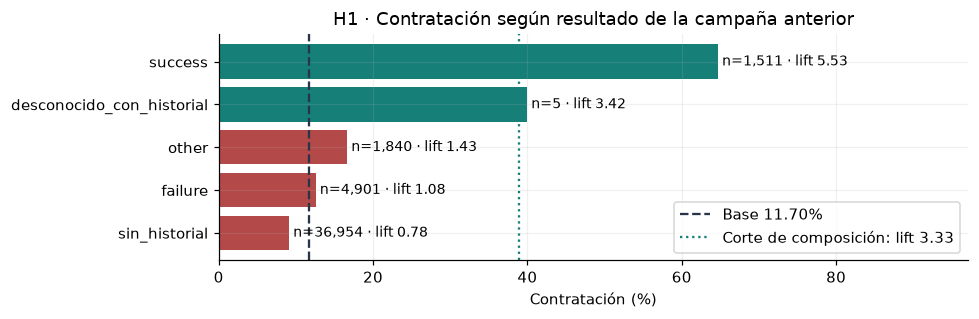

**4. Resultado:** `success`: n=1,511, tasa=64.73%, lift=**5.533**, zona **verde**.

In [6]:
t_h1 = tasas(poutcome_limpio)
display(t_h1.round(4))
grafico_tasas(t_h1,'H1 · Contratación según resultado de la campaña anterior')
h1 = float(t_h1.loc['success','lift']); z_h1=semaforo_composicion(h1)
display(Markdown(f'**4. Resultado:** `success`: n={int(t_h1.loc["success","n"]):,}, '
                 f'tasa={t_h1.loc["success","tasa"]:.2%}, lift=**{h1:.3f}**, zona **{z_h1}**.'))
assert z_h1 == 'verde', 'Si cambian los datos, revisar la conclusión de H1.'
resumen_fichas.append(['H1','Negocio',f'lift {h1:.3f}',z_h1,0,'Confirmada: mayor tasa, no causalidad'])

**5. Movimientos: ninguno.** El resultado verde cierra la ficha.

**6. Qué hago con eso.** Hipótesis confirmada para esta asociación descriptiva. El éxito previo identifica
un segmento de alta tasa observada; no demuestra que volver a llamarlo cause una contratación.
`poutcome` entra como candidata categórica porque precede a la campaña actual. Se conservan por separado
`sin_historial` y `desconocido_con_historial`, sin convertir esos cinco faltantes en «nunca contactado».
La utilidad operativa se validará fuera de muestra; el alto lift no dice que cubra a la mayoría de clientes.
**Advertencia de tamaño:** los cinco casos `desconocido_con_historial` también pueden superar un corte
numérico de lift, pero esa muestra es demasiado pequeña para defender un segmento comercial estable.
Se muestran por transparencia; no forman otra hipótesis ni una recomendación de focalización.

## 5 · Ficha 2 — E3: ¿`campaign` y `previous` repiten información?
**Pregunta: predicción.** ¿Descartar una por redundancia con la otra?

**1. Afirmación.** Los conteos presentan una asociación lineal o monotónica fuerte, compatible con que
midan casi lo mismo. Es una prueba de esa forma de redundancia, no de equivalencia predictiva completa.

**2. Qué espero ver.** Una nube con tendencia marcada y |Pearson| o |Spearman| > 0,6.

**3. Medida y gráfico.** Ambos coeficientes sobre todas las filas. Dos vistas de la nube: rango completo
y zoom hasta percentil 99. El zoom es sólo visual; no elimina observaciones del cálculo.

,coeficiente,valor,zona
0,Pearson,-0.033,rojo
1,Spearman,-0.108,rojo


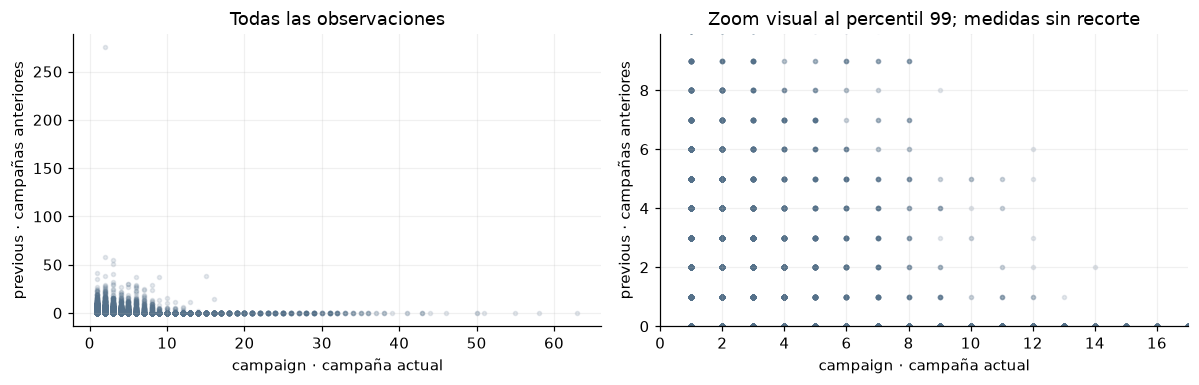

**4. Resultado:** Pearson **-0.033**; Spearman **-0.108**. Zona de la mayor asociación absoluta: **rojo**.

In [7]:
asoc_e3 = asociacion(df['campaign'], df['previous'])
r = float(asoc_e3['pearson'])
rho = float(asoc_e3['spearman'])
display(pd.DataFrame({'coeficiente':['Pearson','Spearman'],'valor':[r,rho],
                      'zona':[semaforo(r,'correlacion'),semaforo(rho,'correlacion')]}).round(4))
fig,axes=plt.subplots(1,2,figsize=(11,3.6))
for ax in axes:
    ax.scatter(df.campaign,df.previous,s=7,alpha=.15,color='#55718a')
    ax.set(xlabel='campaign · campaña actual',ylabel='previous · campañas anteriores')
axes[0].set_title('Todas las observaciones')
axes[1].set(xlim=(0,df.campaign.quantile(.99)+1),ylim=(0,df.previous.quantile(.99)+1),
            title='Zoom visual al percentil 99; medidas sin recorte')
plt.tight_layout();plt.show()
z_e3 = semaforo(max(abs(r),abs(rho)),'correlacion')
display(Markdown(f'**4. Resultado:** Pearson **{r:.3f}**; Spearman **{rho:.3f}**. '
                 f'Zona de la mayor asociación absoluta: **{z_e3}**.'))
assert z_e3=='rojo', 'Revisar la conclusión si cambian los datos.'
resumen_fichas.append(['E3','Predicción',f'r={r:.3f}; rho={rho:.3f}',z_e3,0,
                      'Refutada: no se observa redundancia lineal/monotónica fuerte'])

**5. Movimientos: ninguno.** Rojo cierra la hipótesis. No se buscan subgrupos después de este resultado.

**6. Qué hago con eso.** Refutamos la asociación fuerte esperada. **No descartamos `previous` por
redundancia con `campaign`**. No afirmamos que sean independientes ni que ambas mejoren cualquier modelo.
`previous` queda como candidata, con `log1p` por su cola larga.
`campaign` se revisa por separado en H4 y en el control temporal: esta correlación no autoriza su uso prellamada.

## 6 · Ficha 3 — E4: ocupación y sobrerrepresentación
**Pregunta: negocio.** ¿Hay ocupaciones con una tasa de contratación muy superior a la global?

**1. Afirmación.** Al menos una ocupación está fuertemente sobrerrepresentada entre quienes contratan,
operacionalizado como **lift ≥ 3,33**.

**2. Qué espero ver.** Al menos una ocupación cuya tasa de contratación sea, como mínimo,
3,33 veces la tasa global. Se comparan todas las ocupaciones.

**3. Medida y gráfico.** Tasa, n, positivos y lift por ocupación. La referencia es la tasa global.
Las barras muestran los tamaños de grupo y el corte de composición. Se aplica un único corte,
sin zona amarilla, sobre el lift sin redondear.

,n,positivos,tasa,lift,zona
grupo,,,,,
student,938,269,0.2868,2.4514,rojo
retired,2264,516,0.2279,1.9482,rojo
unemployed,1303,202,0.1550,1.3252,rojo
management,9458,1301,0.1376,1.1758,rojo
admin.,5171,631,0.1220,1.0431,rojo
self-employed,1579,187,0.1184,1.0123,rojo
sin_registrar,288,34,0.1181,1.0092,rojo
technician,7597,840,0.1106,0.9452,rojo
services,4154,369,0.0888,0.7593,rojo


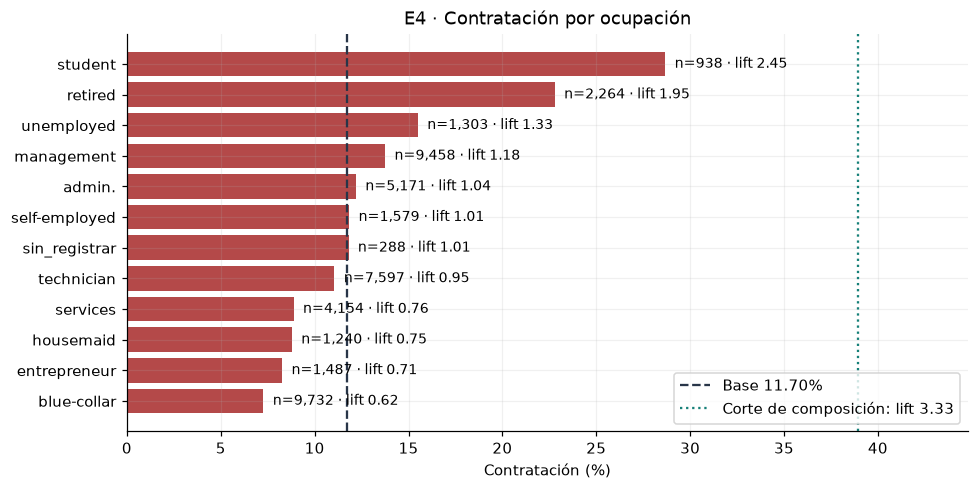

**4. Resultado:** mayor lift **2.451**, correspondiente a **student**; corte **3.33**, zona **rojo**.

In [8]:
t_job = tasas(df.job)
display(t_job.round(4))
grafico_tasas(t_job,'E4 · Contratación por ocupación')
e4_inicial = float(t_job.lift.max())
z_e4 = semaforo_composicion(e4_inicial)
display(Markdown(f'**4. Resultado:** mayor lift **{e4_inicial:.3f}**, '
                 f'correspondiente a **{t_job.lift.idxmax()}**; corte **{CORTE_COMPOSICION:.2f}**, '
                 f'zona **{z_e4}**.'))
assert z_e4 == 'rojo', 'Si cambian los datos, revisar la conclusión de E4.'
resumen_fichas.append(['E4','Negocio',f'lift máximo {e4_inicial:.3f}',z_e4,0,
                       'Refutada bajo el corte 3,33: no alcanza sobrerrepresentación fuerte'])

**5. Movimientos: ninguno.** El resultado rojo cierra la ficha. No se buscan subgrupos para
intentar superar el corte.

**6. Qué hago con eso.** **Refutada bajo el criterio de sobrerrepresentación fuerte fijado.**
La mayor tasa corresponde a `student`, con lift aproximadamente 2,45: supera la tasa global,
pero no alcanza 3,33. Esto **no significa ausencia de asociación** ni que las ocupaciones tengan
la misma tasa; no se confirma la magnitud exigida por la afirmación.

`job` se conserva como **candidata** con One-Hot y categoría desconocida; su utilidad predictiva
se evaluará fuera de muestra. Un resultado rojo para esta hipótesis de negocio no obliga a
eliminar la variable de todo modelo. No se usa el objetivo de todas las filas para fabricar
target encoding ni etiquetas de alta propensión para el futuro conjunto de prueba.

## 7 · Ficha 4 — H4: insistencia y separación de las clases
**Pregunta: predicción.** ¿El conteo de contactos discrimina a quienes contratan?

**1. Afirmación.** `campaign` presenta menor cantidad de contactos entre quienes contratan y separa
las clases suficientemente como para decidir su inclusión por sí sola.

**2. Qué espero ver.** Tasas decrecientes por cantidad de contactos y una separación que supere 0,2;
si queda amarilla, el tamaño aún no resuelve la decisión.

**3. Medida y gráfico.** Separación estandarizada y tasas por intervalos. Se mide `campaign` tal como
está registrada **retrospectivamente**. El análisis no habilita su uso antes de llamar: el conteo incluye
el último contacto y será excluido del primer conjunto de predictores.

,n,positivos,tasa,lift,zona
grupo,,,,,
"(0.0, 1.0]",17544,2561,0.1460,1.2478,rojo
"(1.0, 2.0]",12505,1401,0.1120,0.9577,rojo
"(2.0, 3.0]",5521,618,0.1119,0.9568,rojo
"(3.0, 5.0]",5286,456,0.0863,0.7374,rojo
"(5.0, 10.0]",3159,206,0.0652,0.5574,rojo
"(10.0, inf]",1196,47,0.0393,0.3359,rojo


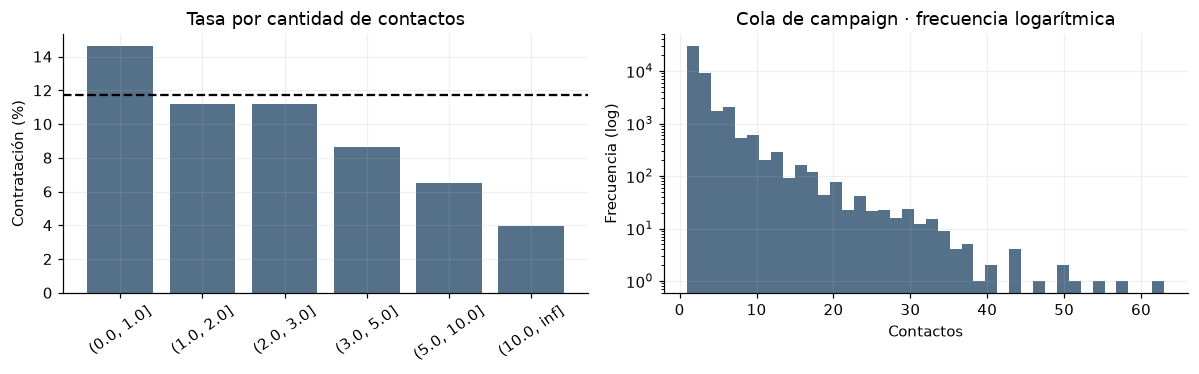

4. Resultado inicial: separación=0.266, zona=amarillo
Skew de campaign: 4.899


In [9]:
h4_inicial=separacion(df.loc[y.eq(1), 'campaign'], df.loc[y.eq(0), 'campaign'])
tramos=pd.cut(df.campaign,[0,1,2,3,5,10,np.inf],right=True)
tasas_campaign=tasas(tramos.astype(str)).reindex([str(v) for v in tramos.cat.categories])
display(tasas_campaign.round(4))
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
axes[0].bar(tasas_campaign.index,tasas_campaign.tasa*100,color='#55718a')
axes[0].axhline(base*100,ls='--',color='black');axes[0].tick_params(axis='x',rotation=35)
axes[0].set(title='Tasa por cantidad de contactos',ylabel='Contratación (%)')
axes[1].hist(df.campaign,bins=40,color='#55718a');axes[1].set_yscale('log')
axes[1].set(title='Cola de campaign · frecuencia logarítmica',xlabel='Contactos',ylabel='Frecuencia (log)')
plt.tight_layout();plt.show()
print(f'4. Resultado inicial: separación={h4_inicial:.3f}, zona={semaforo(h4_inicial,"separacion")}')
print('Skew de campaign:',round(float(df.campaign.skew()),3))
assert semaforo(h4_inicial,'separacion')=='amarillo'

**5. Movimiento 1 — cambiar escala.** El gráfico muestra una cola de conteos grandes y una caída de
tasas concentrada en los primeros contactos. Se aplica `log1p(campaign)` para comprimir esa cola.

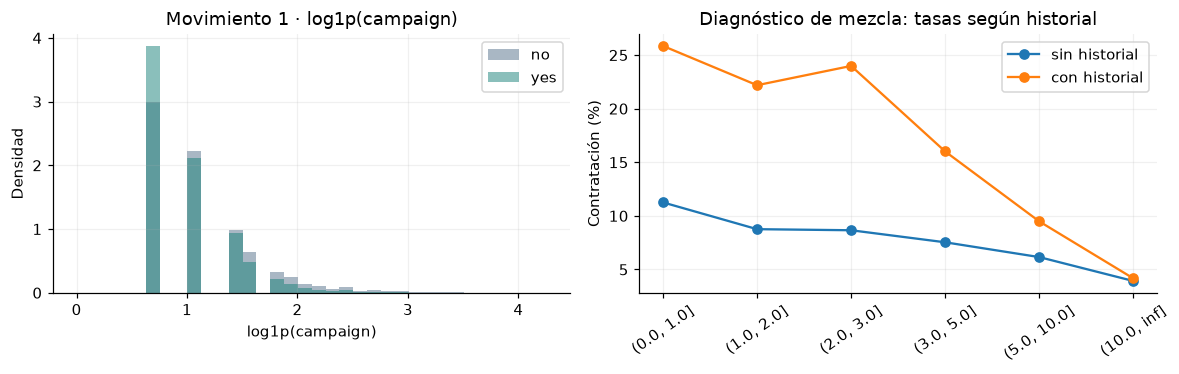

Resultado movimiento 1: 0.291 (amarillo)


In [10]:
campaign_log=np.log1p(df.campaign)
h4_m1=separacion(campaign_log[y.eq(1)], campaign_log[y.eq(0)])
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
bins=np.linspace(0,campaign_log.max()+.1,35)
for val,lab,color in [(0,'no','#55718a'),(1,'yes','#168078')]:
    axes[0].hist(campaign_log[y.eq(val)],bins=bins,density=True,alpha=.5,label=lab,color=color)
axes[0].legend();axes[0].set(title='Movimiento 1 · log1p(campaign)',xlabel='log1p(campaign)',ylabel='Densidad')
for mask,lab in [(~historial,'sin historial'),(historial,'con historial')]:
    tmp=pd.DataFrame({'tramo':tramos[mask], 'y':y[mask]}).groupby('tramo',observed=True).y.mean()
    axes[1].plot(np.arange(len(tmp)),tmp*100,marker='o',label=lab)
axes[1].set_xticks(np.arange(len(tramos.cat.categories)),[str(v) for v in tramos.cat.categories],rotation=35)
axes[1].set(title='Diagnóstico de mezcla: tasas según historial',ylabel='Contratación (%)');axes[1].legend()
plt.tight_layout();plt.show()
print(f'Resultado movimiento 1: {h4_m1:.3f} ({semaforo(h4_m1,"separacion")})')
assert semaforo(h4_m1,'separacion')=='amarillo'

**Movimiento 2 — partir por historial.** El segundo panel distingue curvas para clientes con y sin
historial previo. Se prueba si esa mezcla ocultaba separación. Se informan **los dos grupos**, no sólo
el que mejora; tener historial no se interpreta como asignación aleatoria ni como control causal.

,grupo,n,separación,zona
0,sin historial,36954,0.2387,amarillo
1,con historial,8257,0.2263,amarillo


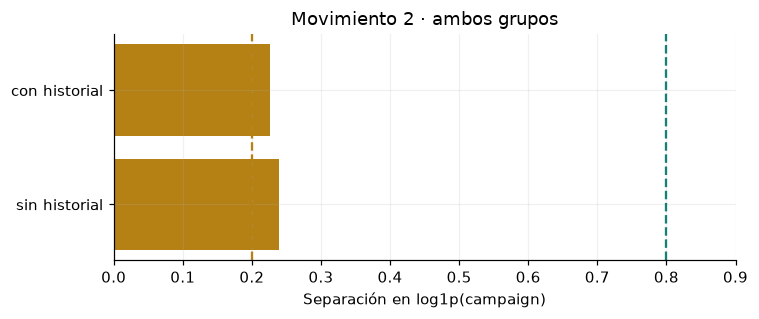

In [11]:
h4_grupos=[]
for mask,lab in [(~historial,'sin historial'),(historial,'con historial')]:
    v=separacion(campaign_log[mask & y.eq(1)], campaign_log[mask & y.eq(0)])
    h4_grupos.append([lab,int(mask.sum()),v,semaforo(v,'separacion')])
h4_final=pd.DataFrame(h4_grupos,columns=['grupo','n','separación','zona'])
display(h4_final.round(4))
fig,ax=plt.subplots(figsize=(7,3))
ax.barh(h4_final.grupo,h4_final['separación'],color=[COLORES[z] for z in h4_final.zona])
ax.axvline(.2,ls='--',color=COLORES['amarillo']);ax.axvline(.8,ls='--',color=COLORES['verde'])
ax.set(xlabel='Separación en log1p(campaign)',title='Movimiento 2 · ambos grupos',xlim=(0,.9))
plt.tight_layout();plt.show()
assert 'verde' not in set(h4_final.zona) and 'amarillo' in set(h4_final.zona)
resumen_fichas.append(['H4','Predicción',f'{h4_inicial:.3f} → {h4_m1:.3f}; ver ambos grupos',
                       'amarillo',2,'Inconclusa; campaign excluida del modelo prellamada inicial'])

**6. Qué hago con eso.** **Inconclusa en poder discriminante.** Se agotaron dos movimientos sin una
separación verde que resuelva la inclusión. No puede inferirse que llamar más cause menos contrataciones:
quienes ya aceptaron pueden dejar de recibir llamadas (regla de parada/selección).

**Decisión temporal:** `campaign` sale del modelo prellamada inicial. `campaign - 1` sería un conteo
anterior al **último** contacto si la fila y el objetivo corresponden exactamente a ese momento;
restar uno no garantiza reconstruir un snapshot válido para cualquier llamada o el inicio de campaña.
Se reconsiderará sólo con una definición verificable del momento de predicción y registros históricos.
Ser amarilla no es el motivo de exclusión temporal; son dos evaluaciones distintas.

## 8 · Tabla de columnas y chequeo de fuga
Decisiones para un **primer modelo conservador previo a la llamada**, no una selección óptima demostrada.
Las zonas auxiliares de abajo se calculan con la medida indicada y **no son nuevas fichas**.
No se comparan como si un lift y una separación fueran la misma escala.

**`duration` sale sin probar ninguna hipótesis:** sólo se conoce al terminar la llamada.
No se borran filas. También se excluyen sus transformaciones y variables que dependan de ella.
Canal y día/mes del último contacto podrían usarse si fueran campos del plan conocido al decidir,
pero el CSV no distingue plan de ejecución: se excluyen de esta primera versión por prudencia.

In [12]:
signlog = lambda s: np.sign(s)*np.log1p(np.abs(s))
especificacion = [
 ('contact_id','ID de registro','Sale: identificador, no atributo del cliente','Sí; no aporta semántica predictiva','No aplica',None,None),
 ('age','Edad en años','Entra: numérica; permitir relaciones no lineales','Sí, dato previo','separacion',separacion(df.loc[y.eq(1), 'age'], df.loc[y.eq(0), 'age']),'age'),
 ('job','Ocupación','Entra: One-Hot + desconocido; candidata, validar aporte','Sí, dato previo','lift',float(t_job.lift.max()),'job'),
 ('marital','Estado civil','Sale del primer modelo: simplificación por efecto marginal débil','Sí, dato previo','eta2',eta2(y, df.marital.fillna('sin_registrar')),None),
 ('education','Nivel educativo','Entra: One-Hot + desconocido; candidata','Sí, dato previo','eta2',eta2(y, df.education.fillna('sin_registrar')),'education'),
 ('default','Mora crediticia','Sale del primer modelo: casi constante, efecto marginal débil','Sí, dato previo','eta2',eta2(y, df.default.fillna('sin_registrar')),None),
 ('balance','Saldo medio anual (€)','Entra como sign(x)*log1p(abs(x)); admite negativos','Sí, saldo histórico disponible','separacion',separacion(signlog(df.loc[y.eq(1), 'balance']), signlog(df.loc[y.eq(0), 'balance'])),'balance_signed_log'),
 ('housing','Préstamo hipotecario','Entra: binaria; contexto e interacciones, no causalidad','Sí, estado previo','eta2',eta2(y, df.housing.fillna('sin_registrar')),'housing'),
 ('loan','Préstamo personal','Entra: binaria; contexto e interacciones','Sí, estado previo','eta2',eta2(y, df.loan.fillna('sin_registrar')),'loan'),
 ('contact','Canal del último contacto','Sale: no se acreditó que sea canal planificado al decidir','No acreditado como dato previo en este CSV','eta2',eta2(y, df.contact.fillna('sin_registrar')),None),
 ('day','Día del último contacto','Sale: metadato del contacto observado','No acreditado como dato planificado','eta2',eta2(y, df.day.astype(str)),None),
 ('month','Mes del último contacto','Sale: metadato observado y posible mezcla temporal','No acreditado como dato planificado','eta2',eta2(y, df.month.fillna('sin_registrar')),None),
 ('duration','Duración de la última llamada','Sale por fuga; también toda transformación','No: se conoce al terminar','separacion',separacion(np.log1p(df.loc[y.eq(1), 'duration']), np.log1p(df.loc[y.eq(0), 'duration'])),None),
 ('campaign','Contactos de la campaña, incluye el último','Sale: snapshot prellamada no acreditado; H4 inconclusa','No garantizado; campaign-1 requiere verificar alineación','separacion',h4_inicial,None),
 ('pdays','Días desde contacto de campaña anterior; -1 nunca','Se reemplaza por tiene_historial + dias_desde_contacto','Sí; historia de campaña anterior','separacion',separacion(df.loc[historial & y.eq(1), 'pdays'], df.loc[historial & y.eq(0), 'pdays']),'derivadas_historial'),
 ('previous','Contactos antes de la campaña actual','Entra log1p: E3 no demuestra redundancia con campaign','Sí; historia previa','separacion',separacion(np.log1p(df.loc[y.eq(1), 'previous']), np.log1p(df.loc[y.eq(0), 'previous'])),'previous_log'),
 ('poutcome','Resultado de campaña anterior','Entra categórica; distingue sin historial y faltante real','Sí; no es el resultado de la campaña actual','lift',h1,'poutcome_limpio'),
 ('y','Contratación yes/no','Objetivo: se separa de X','No: respuesta a predecir','No aplica',None,None)]
tabla=pd.DataFrame(especificacion,columns=['Columna','Qué mide','Decisión','¿Existiría al predecir?',
                                         'Medida','Valor','Salida en X'])
tabla['Zona']=[semaforo_composicion(v) if m=='lift' else semaforo(v,m) if m!='No aplica' else '—'
               for m,v in zip(tabla.Medida,tabla.Valor)]
display(tabla[['Columna','Qué mide','Medida','Valor','Zona','Decisión','¿Existiría al predecir?']].round(4))
print('Fracción de default=no:',round(float(df.default.eq('no').mean()),4))

,Columna,Qué mide,Medida,Valor,Zona,Decisión,¿Existiría al predecir?
0,contact_id,ID de registro,No aplica,NaN,—,"Sale: identificador, no atributo del cliente",Sí; no aporta semántica predictiva
1,age,Edad en años,separacion,0.0695,rojo,Entra: numérica; permitir relaciones no lineales,"Sí, dato previo"
2,job,Ocupación,lift,2.4514,rojo,"Entra: One-Hot + desconocido; candidata, validar aporte","Sí, dato previo"
3,marital,Estado civil,eta2,0.0043,rojo,Sale del primer modelo: simplificación por efecto marginal débil,"Sí, dato previo"
4,education,Nivel educativo,eta2,0.0053,rojo,Entra: One-Hot + desconocido; candidata,"Sí, dato previo"
5,default,Mora crediticia,eta2,0.0005,rojo,"Sale del primer modelo: casi constante, efecto marginal débil","Sí, dato previo"
6,balance,Saldo medio anual (€),separacion,0.3071,amarillo,Entra como sign(x)*log1p(abs(x)); admite negativos,"Sí, saldo histórico disponible"
7,housing,Préstamo hipotecario,eta2,0.0194,rojo,"Entra: binaria; contexto e interacciones, no causalidad","Sí, estado previo"
8,loan,Préstamo personal,eta2,0.0046,rojo,Entra: binaria; contexto e interacciones,"Sí, estado previo"
9,contact,Canal del último contacto,eta2,0.0229,rojo,Sale: no se acreditó que sea canal planificado al decidir,No acreditado como dato previo en este CSV


Fracción de default=no: 0.982


### Preparación determinística, sin entrenar ni ajustar con el objetivo
Se crea una matriz candidata **sin `duration`, sin `campaign` ni metadatos del último contacto**.
Se preservan las filas. `dias_desde_contacto` queda nula sin historial; para modelos que no admitan
nulos, se imputará la mediana **aprendida en train**, conservando `tiene_historial`.
Las categorías se codificarán con One-Hot ajustado sólo en train (desconocidas ignoradas en test).
Tener `tiene_historial` y `poutcome_limpio` puede introducir redundancia parcial: se comparará con/sin
la indicadora mediante validación, no se afirma que el conjunto sea mínimo.

Las decisiones de este análisis se basan en las filas del dataset; por eso, una partición posterior
de estas mismas filas no sería totalmente independiente de la exploración. Para estimar generalización operativa, conviene evaluación
en un período posterior no utilizado. UCI describe bank-full ordenado por fecha; **se debe verificar
que silver conservó ese orden** antes de usarlo como sustituto temporal. `contact_id` no es una fecha.

In [13]:
X = df[['age','job','education','housing','loan']].copy()
for c in ['job','education']: X[c]=X[c].fillna('desconocido')
X['balance_signed_log']=signlog(df.balance)
X['previous_log']=np.log1p(df.previous)
X['tiene_historial']=historial.astype(int)
X['dias_desde_contacto']=df.pdays.where(historial)
X['poutcome_limpio']=poutcome_limpio
assert len(X)==len(y)==len(df)
assert not {'y','contact_id','duration','campaign','contact','day','month'}.intersection(X.columns)
assert X.loc[~historial,'dias_desde_contacto'].isna().all()
assert X.loc[historial,'dias_desde_contacto'].notna().all()
assert (X.loc[inconsistentes,'poutcome_limpio']=='desconocido_con_historial').all()
print('X candidato:',X.shape,'| objetivo:',y.shape)
display(X.head())

X candidato: (45211, 10) | objetivo: (45211,)


,age,job,education,housing,loan,balance_signed_log,previous_log,tiene_historial,dias_desde_contacto,poutcome_limpio
0,58,management,tertiary,yes,no,7.670429,0.0,0,NaN,sin_historial
1,44,technician,secondary,yes,no,3.401197,0.0,0,NaN,sin_historial
2,33,entrepreneur,secondary,yes,yes,1.098612,0.0,0,NaN,sin_historial
3,47,blue-collar,desconocido,yes,no,7.317876,0.0,0,NaN,sin_historial
4,33,desconocido,desconocido,no,no,0.693147,0.0,0,NaN,sin_historial


## 9 · Cierre de las cuatro fichas y defensa

In [14]:
resumen=pd.DataFrame(resumen_fichas,columns=['ID','Pregunta','Medida','Zona','Movimientos','Conclusión'])
assert len(resumen)==4 and set(resumen.Pregunta)=={'Negocio','Predicción'}
assert resumen.Movimientos.le(2).all()
assert resumen.Conclusión.str.contains('Refutada|Inconclusa').any()
assert resumen.set_index('ID').loc['E4','Zona'] == 'rojo'
assert resumen.set_index('ID').loc['E4','Movimientos'] == 0
assert set(t_job.zona).issubset({'rojo','verde'}) and set(t_h1.zona).issubset({'rojo','verde'})
assert tabla.set_index('Columna').loc['job','Zona'] == 'rojo'
assert tabla.set_index('Columna').loc['poutcome','Zona'] == 'verde'
assert set(tabla.Columna)==set(df.columns)
assert not tabla['¿Existiría al predecir?'].isna().any()
display(resumen)
print('Chequeos estructurales de la consigna: OK. La defensa individual no se verifica con código.')

,ID,Pregunta,Medida,Zona,Movimientos,Conclusión
0,H1,Negocio,lift 5.533,verde,0,"Confirmada: mayor tasa, no causalidad"
1,E3,Predicción,r=-0.033; rho=-0.108,rojo,0,Refutada: no se observa redundancia lineal/monotónica fuerte
2,E4,Negocio,lift máximo 2.451,rojo,0,"Refutada bajo el corte 3,33: no alcanza sobrerrepresentación fuerte"
3,H4,Predicción,0.266 → 0.291; ver ambos grupos,amarillo,2,Inconclusa; campaign excluida del modelo prellamada inicial


Chequeos estructurales de la consigna: OK. La defensa individual no se verifica con código.


### Guion de los 20 minutos
| Minutos | Qué mostrar |
|---|---|
| 0–2 | Objetivo de negocio, pregunta predictiva, fuente de datos y alcance del análisis. |
| 2–7 | Perfil calculado: tamaño, clave, tipos, tres nulos principales, distribución de `y` y asimetrías. |
| 7–13 | Dos de las cuatro fichas, elegidas por el docente: afirmación → medida → gráfico → número → decisión. |
| 13–18 | Preguntas individuales. Todos deben poder explicar las cuatro fichas y las exclusiones. |
| 18–20 | Devolución y acciones para la Entrega 3. |

**Preguntas que todos deben poder responder:**
1. ¿Por qué `duration` sale aunque separe muy bien? Porque no existe antes de llamar.
2. ¿Qué no se confirmó? E3 no mostró redundancia fuerte; E4 no alcanzó lift 3,33 y cerró sin movimientos;
   H4 quedó inconclusa tras dos movimientos.
3. ¿Qué nulos son estructurales? `poutcome` sin historial; los faltantes con historial se separan.
4. ¿Qué queda abierto? Generalización fuera de muestra, aporte incremental de las candidatas y
   reconstrucción del snapshot temporal de `campaign`/metadatos.
5. ¿Qué resultado no debemos exagerar? Lift alto no prueba causalidad; correlación baja no prueba independencia.

**Antes de presentar:** reiniciar entorno, ejecutar todo, guardar las salidas y abrir el notebook.
No hay que entrenar un modelo durante estos 20 minutos.

---
## Anexo de reserva · E1 — saldo y contratación
**Análisis complementario, fuera de las cuatro fichas principales.** Explora la relación entre saldo y contratación.
**Pregunta: negocio.** ¿Los registros que terminan en contratación tienen saldos más altos?

**1. Afirmación.** El saldo transformado presenta una diferencia positiva y relevante entre clases.
**2. Qué espero ver.** La distribución de quienes contratan desplazada a la derecha.
**3. Medida y gráfico.** Separación sobre `sign(balance)*log1p(abs(balance))`.
Se fija esa escala porque hay saldos negativos y cola larga, no para mejorar un semáforo.
La transformación conserva el signo y admite ceros. El gráfico se acompaña de tasas por quintil y contexto de deuda.

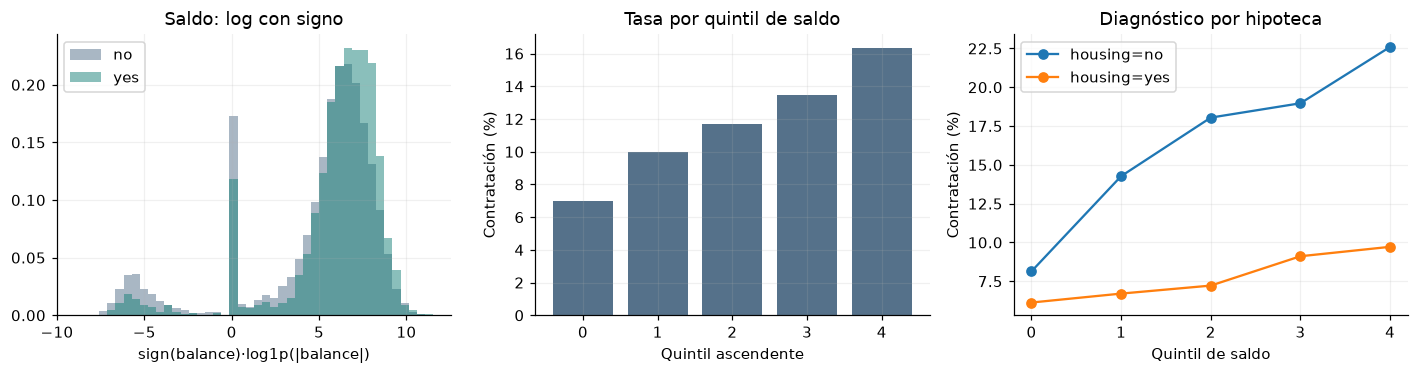

4. Resultado inicial: 0.307 (amarillo)


,size,mean
quintil,,
"(-8019.001, 22.0]",9053,0.0696
"(22.0, 272.0]",9060,0.1000
"(272.0, 701.0]",9017,0.1171
"(701.0, 1859.0]",9039,0.1346
"(1859.0, 102127.0]",9042,0.1637


In [15]:
bal=signlog(df.balance)
e1_base=separacion(bal[y.eq(1)], bal[y.eq(0)])
fig,axes=plt.subplots(1,3,figsize=(13,3.5))
bins=np.linspace(bal.min(),bal.max(),45)
for val,lab,color in [(0,'no','#55718a'),(1,'yes','#168078')]:
    axes[0].hist(bal[y.eq(val)],bins=bins,density=True,alpha=.5,label=lab,color=color)
axes[0].legend();axes[0].set(title='Saldo: log con signo',xlabel='sign(balance)·log1p(|balance|)')
q=pd.qcut(df.balance,5,duplicates='drop')
tq=pd.DataFrame({'quintil':q,'y':y}).groupby('quintil',observed=True).y.agg(['size','mean'])
axes[1].bar(np.arange(len(tq)),tq['mean']*100,color='#55718a')
axes[1].set(title='Tasa por quintil de saldo',xlabel='Quintil ascendente',ylabel='Contratación (%)')
for val in ['no','yes']:
    m=df.housing.eq(val)
    th=pd.DataFrame({'q':q[m],'y':y[m]}).groupby('q',observed=True).y.mean()
    axes[2].plot(np.arange(len(th)),th*100,marker='o',label=f'housing={val}')
axes[2].legend();axes[2].set(title='Diagnóstico por hipoteca',xlabel='Quintil de saldo',ylabel='Contratación (%)')
plt.tight_layout();plt.show()
print(f'4. Resultado inicial: {e1_base:.3f} ({semaforo(e1_base,"separacion")})')
display(tq.round(4))
assert semaforo(e1_base,'separacion')=='amarillo'

**5. Movimiento 1 — partir por hipoteca.** Las curvas del gráfico muestran tasas distintas según
hipoteca; se mide la separación del saldo en las dos ramas manteniendo la misma escala.

,grupo,n,separación,zona
0,housing=no,20081,0.3810,amarillo
1,housing=yes,25130,0.1593,rojo


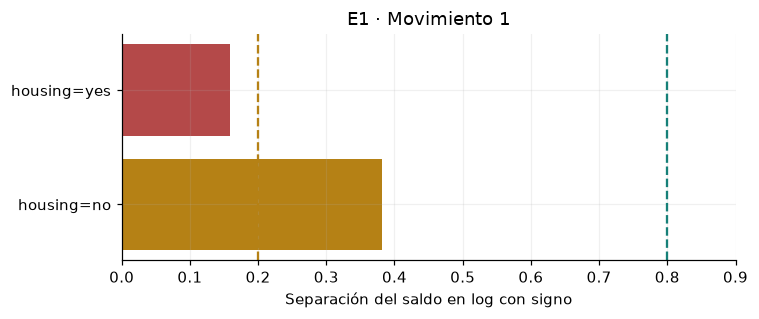

In [16]:
filas=[]
for v in ['no','yes']:
    m=df.housing.eq(v); s=separacion(bal[m & y.eq(1)], bal[m & y.eq(0)])
    filas.append([f'housing={v}',int(m.sum()),s,semaforo(s,'separacion')])
e1_m1=pd.DataFrame(filas,columns=['grupo','n','separación','zona'])
display(e1_m1.round(4))
fig,ax=plt.subplots(figsize=(7,3))
ax.barh(e1_m1.grupo,e1_m1['separación'],color=[COLORES[z] for z in e1_m1.zona])
ax.axvline(.2,ls='--',color=COLORES['amarillo']);ax.axvline(.8,ls='--',color=COLORES['verde'])
ax.set(xlim=(0,.9),title='E1 · Movimiento 1',xlabel='Separación del saldo en log con signo')
plt.tight_layout();plt.show()

**Movimiento 2 — controlar otra deuda en las ramas amarillas.** Si la partición por hipoteca no resuelve
el efecto, se desagrega por préstamo personal, mostrando todas las combinaciones y sin cambiar la escala.
Esto examina heterogeneidad financiera; no identifica un efecto causal del saldo.

In [17]:
filas=[]
for _,rw in e1_m1.iterrows():
    if rw['zona'] != 'amarillo': continue
    hv=rw['grupo'].split('=')[1]
    for lv in ['no','yes']:
        m=df.housing.eq(hv)&df.loan.eq(lv)
        s=separacion(bal[m & y.eq(1)], bal[m & y.eq(0)])
        filas.append([f'housing={hv}, loan={lv}',int(m.sum()),s,semaforo(s,'separacion')])
e1_m2=pd.DataFrame(filas,columns=['grupo','n','separación','zona'])
display(e1_m2.round(4))
assert not e1_m2.empty and 'verde' not in set(e1_m2.zona) and 'amarillo' in set(e1_m2.zona)
print('Resultado final E1: inconclusa bajo los cortes; persisten ramas amarillas tras dos movimientos.')

,grupo,n,separación,zona
0,"housing=no, loan=no",17204,0.3640,amarillo
1,"housing=no, loan=yes",2877,0.1748,rojo


Resultado final E1: inconclusa bajo los cortes; persisten ramas amarillas tras dos movimientos.


**6. Qué hago con eso.** Inconclusa para una separación fuerte y general. No equivale a «el saldo no
se relaciona con contratar»: las tasas descriptivas y la magnitud son preguntas diferentes.
Se conserva `balance_signed_log` como candidata y se valida su aporte fuera de muestra.
No se borran saldos negativos ni se interpreta el cambio de escala como una intervención económica.

## Fuentes y trazabilidad
- [Consigna Entrega 2](https://docs.google.com/document/d/1U1GioMaOf-6MWderTvzR0MXnLsKMmSXIIvAs2CU38tE/edit).
- [CSV silver para descarga automática: ID indicado por el grupo](https://drive.google.com/file/d/1u41ru5WA5q68hXPKegyCY9Z3lAb7VqMn/view).
- [UCI: Bank Marketing, definiciones de variables](https://archive.ics.uci.edu/dataset/222/bank+marketing).
  Datos de Moro, Rita y Cortez, DOI [10.24432/C5K306](https://doi.org/10.24432/C5K306), CC BY 4.0.

Las celdas calculan las tablas, las medidas y los gráficos a partir del CSV cargado.
El SHA256 informado durante la carga identifica exactamente el archivo de esta ejecución.